# JAX CFD 系统课程 · Lesson 01（重新生成版本）

**从二维扩散方程到第一个可验证的数值求解器**  
学习方式：从基础开始自己写求解器，使用 VS Code + Jupyter Notebook + JAX。

> **运行提示**：按从上到下的顺序执行；代码单元格按 `Shift + Enter`。若前面修改了网格参数，请重新执行下游单元格，或使用 **Restart & Run All**。

**完成本课你应当能够：**
1. 把二维扩散方程离散为五点中心差分 + 显式欧拉格式。
2. 理解 JAX 数组、`.at[]`、`jax.jit`、`lax.fori_loop`。
3. 对比解析解并进行网格收敛性检验。
4. 用 Markdown 中的 LaTeX 记录推导。

**文件说明**：此 Notebook 使用英文文件名，便于浏览器下载及 VS Code 打开。内容按顺序组织，不依赖以前课程的文件。

## 0. VS Code / Jupyter 准备

在 VS Code 终端依次执行（只需安装一次，**不是**在 Python 代码单元格执行）：

```bash
uv init jax-cfd-study
cd jax-cfd-study
uv add jax numpy matplotlib
uv add --dev ipykernel
code .
```

将本 Notebook 放到项目的 `notebooks/` 目录中，打开后右上角点击 **Select Kernel → Python Environments → .venv**。

- macOS/Linux 内核路径通常是 `.venv/bin/python`；Windows 通常是 `.venv\Scripts\python.exe`。
- **Markdown 单元格**：文字与 LaTeX；**Code 单元格**：执行 Python。
- `Shift + Enter`：运行当前单元格并移到下一格；`Ctrl + Enter`：只运行当前单元格。
- 若显示 `ModuleNotFoundError`：优先检查内核解释器是否为项目 `.venv`，不建议直接在 Notebook 里随手安装到不明环境。

## 1. 科学问题：二维扩散方程

我们未来要研究不可压缩 Navier–Stokes 方程的黏性项。今天先求解标量场 $u(x,y,t)$：

$$
\boxed{\frac{\partial u}{\partial t}=\nu\nabla^2 u
=\nu\left(\frac{\partial^2u}{\partial x^2}+\frac{\partial^2u}{\partial y^2}\right)}
$$

在 $\Omega=[0,1]\times[0,1]$ 上，使用零 Dirichlet 边界条件：

$$
\begin{aligned}
\nu &=0.1,\\
u(x,y,0)&=\sin(\pi x)\sin(\pi y),\\
u|_{\partial\Omega}&=0.
\end{aligned}
$$

这里 $u$ 是标量（如温度扰动），$\nu$ 是常数扩散系数。**注意这不是完整的 Navier–Stokes 方程**。

### LaTeX 随手学
- `$...$`：行内公式；`$$...$$`：独立公式。
- `\partial`：偏微分符号 $\partial$；`\nabla`：$\nabla$；`\nu`：$\nu$。
- `\frac{分子}{分母}`：分数；`u_{i,j}^{n+1}`：同时写下标与上标。
- `\begin{aligned}...\end{aligned}`：多行对齐，`&` 设置对齐点，`\\` 表示换行。

In [1]:
import sys
import time
from functools import partial

import numpy as np
import jax
import jax.numpy as jnp
from jax import lax
import matplotlib.pyplot as plt

# 本课使用 double precision，便于观察误差收敛（CPU 教学环境）
jax.config.update("jax_enable_x64", True)

print("Python:", sys.version.split()[0])
print("JAX:", jax.__version__)
print("Devices:", jax.devices())
print("浮点类型:", jnp.asarray(1.0).dtype)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Python: 3.12.16
JAX: 0.12.0.1
Devices: [CpuDevice(id=0)]
浮点类型: float64


## 2. 建立空间网格与初始条件

将 $[0,1]$ 等距分成 $N-1$ 个小区间：

$$
\Delta x=\frac{L_x}{N_x-1},\qquad
\Delta y=\frac{L_y}{N_y-1},\qquad
u_{i,j}\approx u(x_i,y_j).
$$

- 本课数组约定 `u[i, j]` 对应物理位置 $(x_i,y_j)$。
- `meshgrid(..., indexing="ij")` 保持这个对应关系。
- 包含边界点的网格大小是 $N_x\times N_y$；内点是 `1:-1`。

In [2]:
nx = ny = 65
Lx = Ly = 1.0
nu = 0.1
t_end = 0.1

x = jnp.linspace(0.0, Lx, nx)
y = jnp.linspace(0.0, Ly, ny)
dx = Lx / (nx - 1)
dy = Ly / (ny - 1)

X, Y = jnp.meshgrid(x, y, indexing="ij")
u0 = jnp.sin(jnp.pi * X) * jnp.sin(jnp.pi * Y)

print("形状", u0.shape, "dx =", dx, "dy =", dy)
print("边界最大绝对值:", float(jnp.max(jnp.abs(u0[0, :]))))

形状 (65, 65) dx = 0.015625 dy = 0.015625
边界最大绝对值: 0.0


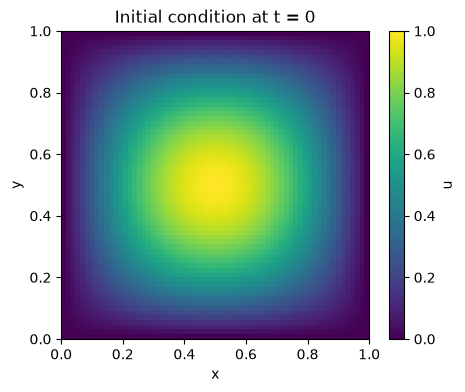

In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(np.asarray(u0).T, origin="lower", extent=(0, Lx, 0, Ly), cmap="viridis")
ax.set(xlabel="x", ylabel="y", title="Initial condition at t = 0")
fig.colorbar(im, ax=ax, label="u")
plt.show()

## 3. 空间离散：五点中心差分

泰勒展开得到：

$$
\frac{\partial^2 u}{\partial x^2}\bigg|_{i,j}
\approx\frac{u_{i+1,j}-2u_{i,j}+u_{i-1,j}}{\Delta x^2}.
$$

同理，$y$ 方向差分：

$$
\frac{\partial^2 u}{\partial y^2}\bigg|_{i,j}
\approx\frac{u_{i,j+1}-2u_{i,j}+u_{i,j-1}}{\Delta y^2}.
$$

两者相加：

$$
\boxed{(\nabla_h^2u)_{i,j}=
\frac{u_{i+1,j}-2u_{i,j}+u_{i-1,j}}{\Delta x^2}
+\frac{u_{i,j+1}-2u_{i,j}+u_{i,j-1}}{\Delta y^2}}
$$

**五点模板**：四个邻点 + 一个中心点。二阶中心差分的空间截断误差是 $O(\Delta x^2+\Delta y^2)$。

### 对应的 JAX 切片

| 数学量 | JAX 表达式 |
|---|---|
| $u_{i,j}$ | `u[1:-1, 1:-1]` |
| $u_{i+1,j}$ | `u[2:, 1:-1]` |
| $u_{i-1,j}$ | `u[:-2, 1:-1]` |
| $u_{i,j+1}$ | `u[1:-1, 2:]` |
| $u_{i,j-1}$ | `u[1:-1, :-2]` |

In [4]:
def laplacian(u, dx, dy):
    """五点中心差分的离散 Laplace 算子；边界位置返回 0。"""
    center = u[1:-1, 1:-1]
    d2x = (u[2:, 1:-1] - 2.0 * center + u[:-2, 1:-1]) / dx**2
    d2y = (u[1:-1, 2:] - 2.0 * center + u[1:-1, :-2]) / dy**2
    return jnp.zeros_like(u).at[1:-1, 1:-1].set(d2x + d2y)

lap_num = laplacian(u0, dx, dy)
lap_exact = -2 * jnp.pi**2 * u0
lap_error = float(jnp.max(jnp.abs(lap_num[1:-1,1:-1] - lap_exact[1:-1,1:-1])))
print(f"离散 Laplace 的最大内点误差: {lap_error:.6e}")

离散 Laplace 的最大内点误差: 3.963268e-03


### JAX 语法重点：为什么使用 `.at[]`？

JAX 的数组通常视为**不可变数据**；以下 NumPy 风格的原地写入在 JAX 中并不适用：

```python
u[1:-1, 1:-1] = values    # JAX 数组不能这样直接赋值
```

应该使用函数式更新：

```python
u_new = u.at[1:-1, 1:-1].set(values)
```

**理解重点**：`u_new` 是更新结果，原始 `u` 不需要被原地修改。注意，编译器仍然可能在底层优化这些操作。

## 4. 时间离散：显式欧拉法

用前向差分近似时间导数：

$$
\frac{\partial u}{\partial t}\bigg|_{t_n}
\approx\frac{u_{i,j}^{n+1}-u_{i,j}^n}{\Delta t}.
$$

代回 PDE 得到：

$$
\boxed{u_{i,j}^{n+1}=u_{i,j}^n+\nu\Delta t(\nabla_h^2u^n)_{i,j}}
$$

这叫 **显式时间推进**：右边只依赖已知的第 $n$ 层信息。

### 为什么要遵守稳定性条件？

对二维均匀网格的显式欧拉 + 中心差分，稳定性条件为：

$$
\nu\Delta t\left(\frac{1}{\Delta x^2}+\frac{1}{\Delta y^2}\right)\le\frac12.
$$

若 $\Delta x=\Delta y=h$：

$$\boxed{\Delta t\le \frac{h^2}{4\nu}}.$$

这里用安全系数 $0.8$ 选择一个不超过上限的步长，并调整步数，使结束时刻恰好等于 `t_end`。

In [ ]:
dt_max = 0.5 / (nu * (1.0 / dx**2 + 1.0 / dy**2))
safety = 0.8
nsteps = int(np.ceil(t_end / (safety * dt_max)))
dt = t_end / nsteps

print(f"稳定上限 dt_max = {dt_max:.8f}")
print(f"实际 dt = {dt:.8f}, 时间步数 = {nsteps}")
assert dt <= dt_max, "显式扩散格式不满足稳定性条件"

稳定上限 dt_max = 0.00061035
实际 dt = 0.00048780, 时间步数 = 205


In [6]:
def step(u, dt, dx, dy, nu):
    """一个时间步：扩散更新 + 四边零值 Dirichlet 条件。"""
    u_next = u + nu * dt * laplacian(u, dx, dy)
    return (u_next.at[0, :].set(0.0)
                  .at[-1, :].set(0.0)
                  .at[:, 0].set(0.0)
                  .at[:, -1].set(0.0))

@partial(jax.jit, static_argnames=("nsteps",))
def evolve(u0, dt, dx, dy, nu, nsteps):
    """用 JAX 编译整个时间循环。"""
    return lax.fori_loop(
        0, nsteps,
        lambda i, u: step(u, dt, dx, dy, nu),
        u0,
    )

print("step 与 evolve 已定义。")

step 与 evolve 已定义。


### JAX 语法重点：`jax.jit` 与 `lax.fori_loop`

- `jax.jit`：**即时编译**，将计算图交给编译器优化。首次调用会触发编译，后续相同形状/静态参数调用通常可以复用编译结果。
- `lax.fori_loop`：把迭代写成可供 JAX 追踪、编译的循环，而不是让 Python 每步都参与调度。
- `static_argnames=("nsteps",)`：使循环步数为**静态参数**；修改 `nsteps` 可能触发重新编译。

> **实务提醒**：学习阶段暂时不追求最优速度。之后做大量 CFD 步进时，还需考虑稀疏线性求解、内存、边界处理等核心问题。

In [7]:
# 首次调用会包含 JIT 编译时间。
t0 = time.perf_counter()
u_num = evolve(u0, dt, dx, dy, nu, nsteps)
u_num.block_until_ready()
first_call = time.perf_counter() - t0

# 第二次调用可用于粗略感受编译缓存效果。
t0 = time.perf_counter()
u_again = evolve(u0, dt, dx, dy, nu, nsteps)
u_again.block_until_ready()
second_call = time.perf_counter() - t0

print(f"首次调用（含编译）: {first_call:.4f} s")
print(f"第二次调用（不含首次编译）: {second_call:.4f} s")
print("最终最大值:", float(u_num.max()))

首次调用（含编译）: 0.0514 s
第二次调用（不含首次编译）: 0.0006 s
最终最大值: 0.8208232233115351


## 5. 解析解与误差验证

对本课选择的初始/边界条件，可以用分离变量法得到：

$$
\boxed{u_{\mathrm{exact}}(x,y,t)=e^{-2\pi^2\nu t}\sin(\pi x)\sin(\pi y)}.
$$

我们测量两种误差：

$$
E_{\infty}=\max_{i,j}|u_{i,j}^{\mathrm{num}}-u_{i,j}^{\mathrm{exact}}|,
$$

$$
E_{2}=\sqrt{\frac{1}{N_x N_y}\sum_{i,j}
\left(u_{i,j}^{\mathrm{num}}-u_{i,j}^{\mathrm{exact}}\right)^2}.
$$

注意：这里的 $E_2$ 是**所有网格点上的均方根误差**，不是连续意义下积分型的 $L^2$ 范数。

In [8]:
u_exact = jnp.exp(-2.0 * jnp.pi**2 * nu * t_end) * u0
err = u_num - u_exact
err_max = float(jnp.max(jnp.abs(err)))
err_rms = float(jnp.sqrt(jnp.mean(err**2)))

print(f"L_inf 最大绝对误差: {err_max:.8e}")
print(f"RMS 均方根误差: {err_rms:.8e}")
assert err_max < 1e-3, "误差超过教学用阈值，请检查参数或时间推进"

L_inf 最大绝对误差: 4.54941040e-05
RMS 均方根误差: 2.23970974e-05


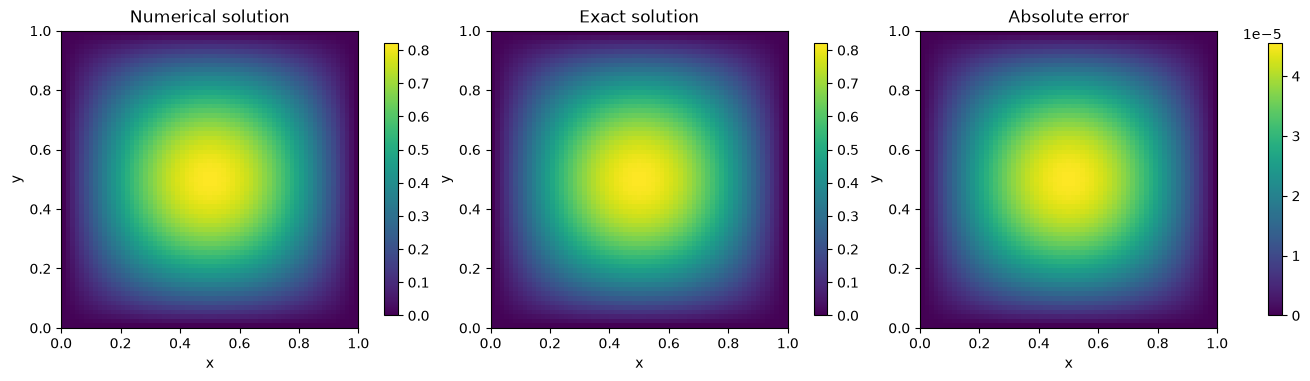

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
fields = [u_num, u_exact, jnp.abs(err)]
titles = ["Numerical solution", "Exact solution", "Absolute error"]
for ax, field, title in zip(axes, fields, titles):
    im = ax.imshow(
        np.asarray(field).T, origin="lower", extent=(0, Lx, 0, Ly),
        cmap="viridis", aspect="equal"
    )
    ax.set(xlabel="x", ylabel="y", title=title)
    fig.colorbar(im, ax=ax, shrink=0.78)
plt.show()

### 为什么绘图时使用 `.T`？

本课规定 `u[i,j]` 中第一个索引代表 $x$，第二个索引代表 $y$。而 Matplotlib 的 `imshow` 默认把数组第一维解释为**纵向行索引**。

因此使用：

```python
plt.imshow(np.asarray(u).T, origin="lower", extent=(0, 1, 0, 1))
```

将数组转置后，图像横轴才对应 $x$，纵轴对应 $y$。若以后改用其它网格布局，要始终保持索引约定和绘图习惯一致。

## 6. 网格收敛性实验

理论上，中心差分的空间误差为 $O(h^2)$，显式欧拉的时间误差为 $O(\Delta t)$，因此：

$$ E=O(h^2)+O(\Delta t). $$

本实验令 $\Delta t\propto h^2$，则预计总体误差近似满足：

$$\boxed{E\propto h^2}. $$

所以把网格步长减半，误差理论上会接近原来的 $1/4$。我们用四种网格测试它。

In [10]:
def run_case(n, nu=0.1, t_end=0.1, safety=0.8):
    h = 1.0 / (n - 1)
    grid = jnp.linspace(0.0, 1.0, n)
    xx, yy = jnp.meshgrid(grid, grid, indexing="ij")
    initial = jnp.sin(jnp.pi * xx) * jnp.sin(jnp.pi * yy)

    dt_max = h**2 / (4.0 * nu)
    steps = int(np.ceil(t_end / (safety * dt_max)))
    actual_dt = t_end / steps
    numerical = evolve(initial, actual_dt, h, h, nu, steps)
    exact = initial * jnp.exp(-2 * jnp.pi**2 * nu * t_end)
    e = float(jnp.max(jnp.abs(numerical - exact)))
    return h, e, steps

sizes = [17, 33, 65, 129]
results = [run_case(n) for n in sizes]
h_values = np.array([r[0] for r in results])
errors = np.array([r[1] for r in results])

for n, (h, error, steps) in zip(sizes, results):
    print(f"N={n:3d} | h={h:.6f} | steps={steps:4d} | max_error={error:.6e}")

slope = np.polyfit(np.log(h_values), np.log(errors), 1)[0]
print(f"\n拟合的收敛阶数 p ≈ {slope:.3f}")

N= 17 | h=0.062500 | steps=  13 | max_error=7.145321e-04
N= 33 | h=0.031250 | steps=  52 | max_error=1.777029e-04
N= 65 | h=0.015625 | steps= 205 | max_error=4.549410e-05
N=129 | h=0.007812 | steps= 820 | max_error=1.136975e-05

拟合的收敛阶数 p ≈ 1.989


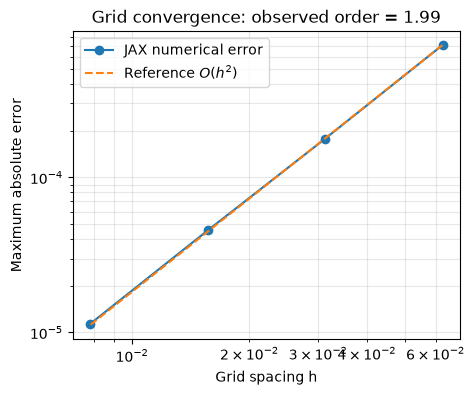

In [11]:
plt.figure(figsize=(5, 4))
plt.loglog(h_values, errors, "o-", label="JAX numerical error")
plt.loglog(h_values, errors[0] * (h_values / h_values[0])**2,
           "--", label=r"Reference $O(h^2)$")
plt.xlabel("Grid spacing h")
plt.ylabel("Maximum absolute error")
plt.title(f"Grid convergence: observed order = {slope:.2f}")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

## 7. 学会写 LaTeX：常用符号速查

| 想显示 | 在 Markdown 的 `$$...$$` 内写 |
|---|---|
| $\alpha,\beta,\nu,\rho$ | `\alpha,\beta,\nu,\rho` |
| $\Delta x$ | `\Delta x` |
| $\frac{\partial u}{\partial t}$ | `\frac{\partial u}{\partial t}` |
| $u_{i,j}^{n+1}$ | `u_{i,j}^{n+1}` |
| $\nabla^2u$ | `\nabla^2 u` |
| $\boldsymbol{u}$ | `\boldsymbol{u}` |
| $\sum_{i=1}^{N}u_i$ | `\sum_{i=1}^{N}u_i` |
| $\left(\frac ab\right)^2$ | `\left(\frac{a}{b}\right)^2` |
| $\underbrace{a+b}_{\text{注释}}$ | `\underbrace{a+b}_{\text{注释}}` |

**规则**：命令用反斜杠 `\` 引入；花括号 `{}` 用于分组；下划线 `_` 是下标、插入符号 `^` 是上标；`\text{}` 可在数学环境写自然语言。

**Markdown 渲染要点**：如果把公式放入 ` ```latex ... ``` ` 代码围栏中，只会显示源码，不会渲染；直接使用 `$...$` 或 `$$...$$` 才会显示数学公式。

**Matplotlib 标注公式**：

```python
plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,y,t)$")
```

这里 `r"..."` 是 Python 的 raw string（原始字符串），能减少反斜杠被当作转义字符的麻烦。

## 8. 练习

- [ ] **练习 A（基础）**：将扩散系数由 `0.1` 改为 `0.05`、`0.2`，思考峰值随扩散系数变化的原因。
- [ ] **练习 B（核心）**：自行写出 `laplacian` 的五点公式，不查看上面代码，再和结果对比。
- [ ] **练习 C（验证）**：把 `sizes` 修改为 `[17, 33, 65, 129]` 并检查 log-log 图上的斜率是否接近 `2`。
- [ ] **练习 D（稳定性）**：尝试略超过理论稳定上限的步长。**注意**：平滑的单一正弦模态可能短时间内仍表现正常，因为高频不稳定模态未被充分激发。若要观察不稳定，应考虑添加小幅高频扰动并延长时间；先备份正常参数。
- [ ] **练习 E（进阶）**：给定固定 `dt` 和 `nsteps`，把终点误差定义为损失，对 $\nu$ 使用 `jax.grad` 求梯度。计算梯度时不要把离散取整 `ceil` 放进关于 $\nu$ 的可微路径。

### 自检问答

1. 为什么单纯减小 $\Delta x$，显式方法通常必须同时减小 $\Delta t$？
2. `u[2:,1:-1]` 在数学上对应哪个网格量？
3. `jax.jit` 第一次运行比较慢，是否代表 JAX 的数值计算更慢？
4. 为什么必须有解析解或独立基准结果？只画出流场图是否足够？
5. 为什么不能直接把现在的扩散代码称为完整的圆柱绕流求解器？

## 9. Jupyter 使用注意事项

- **代码顺序**：Notebook 变量是内核状态，不是按页面顺序自动更新。修改了上游参数，必须重新运行相关下游代码。
- **可信复现**：交作业/保存关键实验前，使用 `Restart Kernel` → `Run All`，确保没有依赖隐藏的旧变量。
- **内核选择**：若 `import jax` 报错，先检查右上角 `Select Kernel` 指向的 `.venv`。
- **编译耗时**：`jit` 首次运行包含编译时间；性能评估使用 `block_until_ready()`。
- **Notebook 与正式求解器分工**：现在在 Notebook 中探索；后续将 Laplace、梯度、散度、时间推进等函数逐步转到 `src/` 模块中。

### 本课结论

我们第一次把 PDE 转换为了可执行的 JAX 数值算法，并且用解析解、网格收敛性检验结果。下一课引入**对流项**，重点研究数值耗散、迎风格式和 CFL 条件。